# 🎓 第5章 第3课：特质波动率（IVOL）

**本节目标**：检验“特质波动率之谜”：

- 用 FF3 回归的残差波动率衡量“特质风险”；
- 按 IVOL 分组，做多低 IVOL、做空高 IVOL；
- 看低波动组是否反而收益更高（负相关）。

对应原书 5.3 节。

> ⚠️ IVOL 使用真实价格 + 第3章因子（部分因子为教学面板），样本仅 87 只股票；
> 结果仅用于演示方法，不代表真实 A 股结论。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.data import load_ashare_panel
from factor_zero.anomalies import (
    make_teaching_fundamentals, piotroski_f_score,
    distance_from_52w_high, rolling_ivol,
)
from factor_zero.factors import build_factor_returns
from factor_zero.sorting import long_short_factor, monotonicity_test, quantile_group, sort_portfolios
from factor_zero.statistics import factor_summary, nw_t_stat

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


In [2]:
panel = load_ashare_panel()
ret = panel['ret']
factors = build_factor_returns(panel, n_groups=10)
ff3 = factors[['MKT', 'SMB', 'HML']]
ivol = rolling_ivol(ret, ff3, window=24)
print('IVOL 面板:', ivol.shape)
print('有效观测:', int(ivol.notna().sum().sum()))
ivol.stack().describe().round(4)

IVOL 面板: (83, 81)
有效观测: 4860


count    4860.0000
mean        0.2652
std         0.1091
min         0.0533
25%         0.1858
50%         0.2520
75%         0.3318
max         0.6883
dtype: float64

## 1) IVOL 的直觉

- **特质风险**：不能被市场/规模/价值解释的个股波动；
- 传统金融：高风险应该高收益；
- 实证谜题：高 IVOL 股票的未来收益反而更低（IVOL 负相关）；
- 解释：套利限制 + 投资者偏好彩票型股票 → 高 IVOL 被高估。

下面用分组检验看这个关系。

低IVOL − 高IVOL: 月均 -1.221%，年化 -14.65%，NW t=-1.10
分组单调性 rho=0.68（组1=低IVOL，组10=高IVOL）


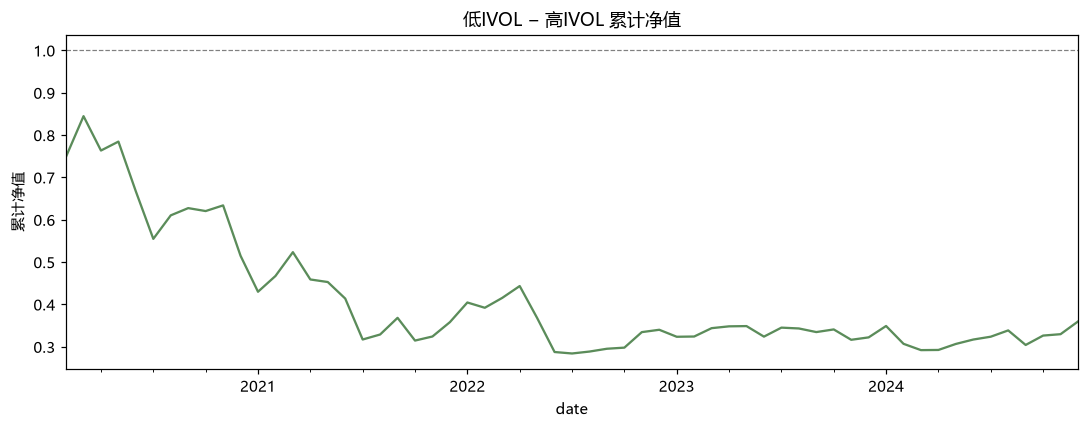

In [3]:
f_ivol, port_ivol, _ = long_short_factor(ivol, ret, n_groups=10, high_minus_low=False)
s_ivol = factor_summary(f_ivol)
rho_ivol = monotonicity_test(port_ivol)['rho']
print(f'低IVOL − 高IVOL: 月均 {f_ivol.mean()*100:+.3f}%，年化 {s_ivol["mean_ann"]*100:+.2f}%，NW t={s_ivol["t_stat"]:.2f}')
print(f'分组单调性 rho={rho_ivol:.2f}（组1=低IVOL，组10=高IVOL）')
((1 + f_ivol).cumprod()).plot(figsize=(10, 4), color='#5B8C5A', title='低IVOL − 高IVOL 累计净值')
plt.axhline(1, color='gray', lw=.8, ls='--'); plt.ylabel('累计净值'); plt.tight_layout(); plt.show()

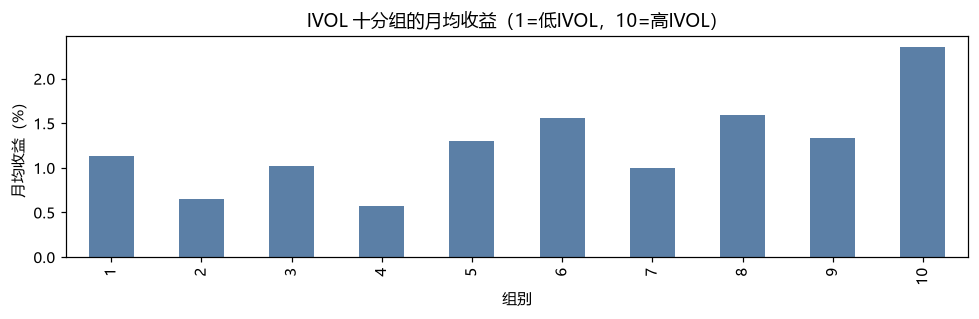

1     1.136
2     0.645
3     1.015
4     0.574
5     1.294
6     1.556
7     0.995
8     1.593
9     1.334
10    2.357
dtype: float64

In [4]:
means = port_ivol.mean() * 100
means.plot(kind='bar', figsize=(9, 3), color='#5B7FA6')
plt.title('IVOL 十分组的月均收益（1=低IVOL，10=高IVOL）')
plt.xlabel('组别'); plt.ylabel('月均收益（%）'); plt.tight_layout(); plt.show()
means.round(3)

> 🔍 **本例结果与经典 IVOL 之谜相反**：低 IVOL − 高 IVOL 为负、rho≈+0.68，
> 即高 IVOL 组反而收益更高。这说明异象对样本、窗口、因子模型很敏感；
> 不要把单一结果当规律，也不要因此否定原书/文献的结论。


## 2) 控制市值：IVOL 会不会只是小盘股的“马甲”？

先按市值分 3 层，每层内按 IVOL 分 5 组，算“低 IVOL − 高 IVOL”。
如果每层内价差仍然存在，说明 IVOL 不是规模因子的替身。

In [5]:
common = ret.index.intersection(ivol.index).intersection(panel['size'].index)
spreads = {1: [], 2: [], 3: []}
for t in range(len(common) - 1):
    d, dn = common[t], common[t + 1]
    sg = quantile_group(panel['size'].loc[d].dropna(), n_groups=3)
    for layer in [1, 2, 3]:
        inside = sg[sg == layer].index
        iv = ivol.loc[d, inside].dropna()
        if len(iv) < 5:
            continue
        g = quantile_group(iv, n_groups=5)
        sub_ret = ret.loc[[dn], g.index]
        sub_g = g.to_frame().T.copy(); sub_g.index = [dn]
        port_s = sort_portfolios(sub_ret, sub_g, n_groups=5)
        spreads[layer].append(port_s.iloc[0, 0] - port_s.iloc[0, 4])

for layer in [1, 2, 3]:
    s = pd.Series(spreads[layer])
    t_nw, _ = nw_t_stat(s)
    print(f'市值第{layer}层（{"小" if layer==1 else "中" if layer==2 else "大"}）：'
          f'低-高 IVOL {s.mean()*100:+.3f}%/月，NW t={t_nw:.2f}，共{len(s)}期')

市值第1层（小）：低-高 IVOL -1.516%/月，NW t=-1.29，共59期
市值第2层（中）：低-高 IVOL -0.683%/月，NW t=-0.67，共59期
市值第3层（大）：低-高 IVOL -0.862%/月，NW t=-0.84，共59期


## ✋ 试一试

1. 把 IVOL 窗口从 24 个月改成 12 个月，结果怎么变？
2. 用 FF5 而不是 FF3 算残差，IVOL 的显著性怎么变？
3. 把方向换成“高 IVOL − 低 IVOL”，t 值符号怎么变？

## ✅ 本节小结

- IVOL = 多因子回归残差的波动率，衡量特质风险；
- 实证上高 IVOL 往往伴随更低未来收益（IVOL 之谜）；
- 控制市值后仍可能存在，但结果依赖样本、窗口和因子模型；
- 本 notebook 的样本和因子面板有限，结论不能直接外推。

> 下一章：因子研究现状——p-hacking、因子动物园、机器学习。